# ISE-A5 Quality and Security Counterexample Study: reproduction notebook

This notebook re-executes the **frozen procedure** top to bottom, in-process, and checks the fresh verdicts against
the recorded raw results in `results/raw/`. It writes nothing to `results/raw/`; the recorded runs are made by
`harness/run_study.py` (see REPRODUCE.md).

Run from the repository root with the study environment: `.venv\Scripts\jupyter-nbconvert --to notebook --execute --inplace notebook/ISE-A5-Study.ipynb`

In [1]:
import hashlib, json, os, sys, platform
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'PROTOCOL.md').exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / 'harness'))
import db, cases, mutants, run_study
print('python', sys.version.split()[0], '|', platform.platform())
print('cases', len(cases.CASES), '| mutants', len(mutants.MUTANTS))

python 3.12.4 | Windows-11-10.0.22631-SP0
cases 67 | mutants 10


## 1. The code under test is the untouched snapshot

In [2]:
bad = []
for line in (ROOT / 'target' / 'SNAPSHOT-SHA256.txt').read_text().splitlines():
    digest, name = line.split(maxsplit=1)
    p = ROOT / 'target' / 'app-under-test' / name.lstrip('*').removeprefix('./')
    if hashlib.sha256(p.read_bytes()).hexdigest() != digest:
        bad.append(name)
print('snapshot files checked; mismatches:', bad or 'none')
assert not bad

snapshot files checked; mismatches: none


## 2. Frozen inputs match the freeze record

In [3]:
frozen = {}
for line in (ROOT / 'protocol' / 'FROZEN-SHA256.txt').read_text().splitlines():
    d, n = line.split(maxsplit=1); frozen[n.lstrip('*')] = d
for n, d in frozen.items():
    now = hashlib.sha256((ROOT / n).read_bytes()).hexdigest()
    print(('same   ' if now == d else 'CHANGED'), n)
print()
print('Expected: harness/run_study.py differs (D1) and PROTOCOL.md differs (D2, wording only).')
orig = hashlib.sha256((ROOT / 'protocol' / 'PROTOCOL-as-frozen.md').read_bytes()).hexdigest()
print('protocol/PROTOCOL-as-frozen.md equals the frozen PROTOCOL.md hash:', orig == frozen['PROTOCOL.md'])
assert orig == frozen['PROTOCOL.md']

CHANGED PROTOCOL.md
same    THREAT-MODEL.md
same    harness/cases.py
same    harness/db.py
same    harness/mutants.py
CHANGED harness/run_study.py
same    harness/fixtures.sql
same    harness/supabase_shim.sql
same    requirements.txt
same    target/UPSTREAM.md
same    target/SNAPSHOT-SHA256.txt

Expected: harness/run_study.py differs (D1) and PROTOCOL.md differs (D2, wording only).
protocol/PROTOCOL-as-frozen.md equals the frozen PROTOCOL.md hash: True


## 3. Re-run baseline and improved configurations

In [4]:
cluster = db.Cluster()
fresh = {}
try:
    for cfg in ('before', 'after'):
        fresh[cfg] = run_study.run_all(cluster.build(f'nb_{cfg}', db.config_sql(cfg)))
        s = run_study.summarise(fresh[cfg])
        print(f"{cfg:6}: counterexamples={s['counterexamples']}  control_failures={s['control_failures']}  valid={s['run_valid']}")
    m08 = None
finally:
    cluster.close()

unknown PostgreSQL timezone: 'UTC0'; will use UTC


before: counterexamples=['IN-04', 'IN-05', 'IN-10']  control_failures=[]  valid=True


after : counterexamples=[]  control_failures=[]  valid=True


## 4. Fresh verdicts equal the recorded verdicts

In [5]:
def recorded(cfg):
    f = sorted((ROOT / 'results' / 'raw').glob(f'*-{cfg}-run1.json'))[-1]
    return f.name, {r['id']: r['verdict'] for r in json.loads(f.read_text(encoding='utf-8'))['results']}
for cfg in ('before', 'after'):
    name, rec = recorded(cfg)
    diff = [r['id'] for r in fresh[cfg] if rec[r['id']] != r['verdict']]
    print(f'{cfg:6} vs {name}: differences = {diff or "none"}')
    assert not diff

before vs 20261121T123347Z-before-run1.json: differences = none
after  vs 20261121T123544Z-after-run1.json: differences = none


## 5. Counterexamples in detail

In [6]:
for r in fresh['before']:
    if r['counterexample']:
        print(r['id'], r['actor'], 'rows affected =', r['rowcount'], '| state unchanged =', r['state_check'])
print()
print(next(c['sql'] for c in cases.CASES if c['id'] == 'IN-05'))

IN-04 R rows affected = 1 | state unchanged = False
IN-05 R rows affected = 1 | state unchanged = False
IN-10 R rows affected = 1 | state unchanged = False

delete from public.courses where id = '{CR}'


## 6. The bounded improvement

In [7]:
print((ROOT / 'improvement' / '001_require_active_instructor_for_course_writes.sql').read_text())

-- A5 bounded improvement (the only one allowed by PROTOCOL.md section 7).
-- Applied as a migration after the frozen schema; the frozen schema file itself is not edited.
--
-- Counterexamples fixed (baseline run): IN-04 rename, IN-05 delete, IN-10 archive.
-- Cause: courses_update and courses_delete only checked ownership (instructor_id = auth.uid()), not that the
-- owner is still an APPROVED instructor. Every other instructor rule uses public.is_instructor_of(), which does.
-- A revoked instructor could therefore delete their course, and the delete cascades to the students'
-- enrolments, assignments, submissions and grades.
--
-- Change: use the same public.is_instructor_of(id) guard as assignments_* policies.
-- Not changed (deliberately): courses_select. A revoked instructor can still see the name of the course they
-- created; hiding it is a product decision, not needed to remove the counterexamples (see RESIDUAL-RISK.md).

drop policy courses_update on public.courses;
create po

## 7. Comparison (generated from raw results) and figures

In [8]:
import subprocess
print(subprocess.run([sys.executable, 'harness/compare.py'], capture_output=True, text=True, encoding='utf-8').stdout)

# Before / after comparison

_Generated by `python harness/compare.py` from `results/raw/`. Do not edit by hand._

| | Before (frozen app) | After (+ improvement 001) |
|---|---|---|
| Raw files | 20261121T123347Z-before-run1.json, 20261121T123349Z-before-run2.json, 20261121T123351Z-before-run3.json | 20261121T123544Z-after-run1.json, 20261121T123546Z-after-run2.json, 20261121T123548Z-after-run3.json |
| Runs / identical verdicts | 3 / True | 3 / True |
| Cases (attack + control) | 56 + 11 | 56 + 11 |
| Run valid (all controls pass) | True | True |
| **Counterexamples** | **3** (IN-04, IN-05, IN-10) | **0** (-) |
| Control failures (side effects) | 0 | 0 |
| Seconds per run (build + 67 cases) | 1.94–1.97 | 1.85–1.94 |

## Per claim

| Claim | Statement | Attack cases | Counterexamples before | after | Verdict before → after |
|---|---|---|---|---|---|
| C1 | Role, email, status not client-writable | 5 | 0  | 0 | not falsified → not falsified |
| C2 | Deadline only via change_deadline()

fig1-study-flow.png


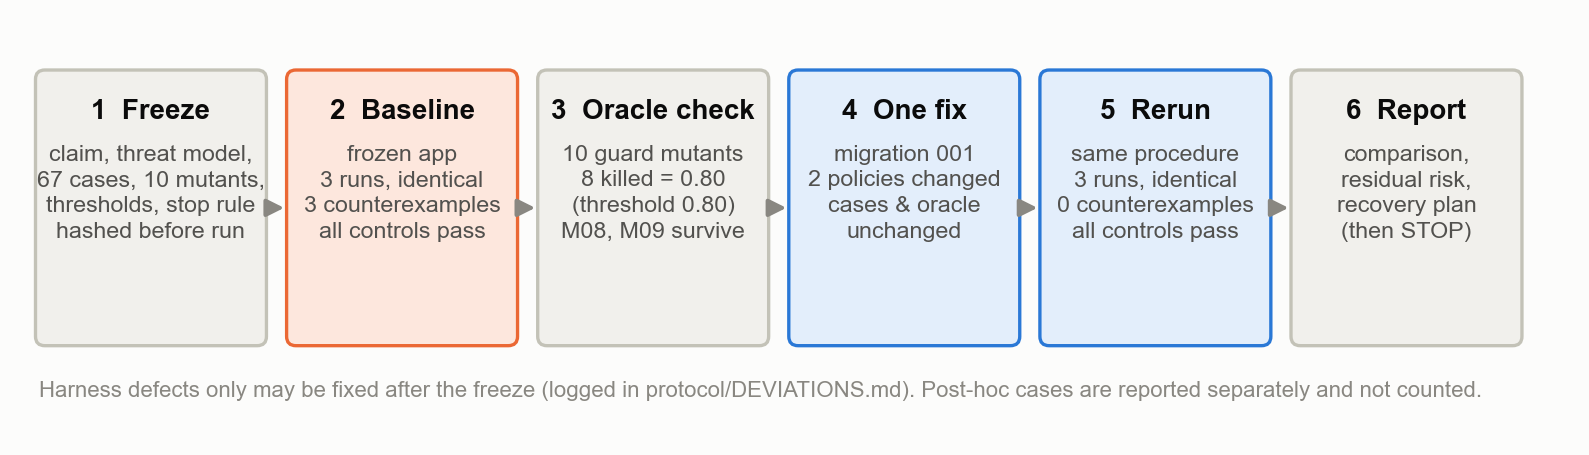

fig2-threat-model.png


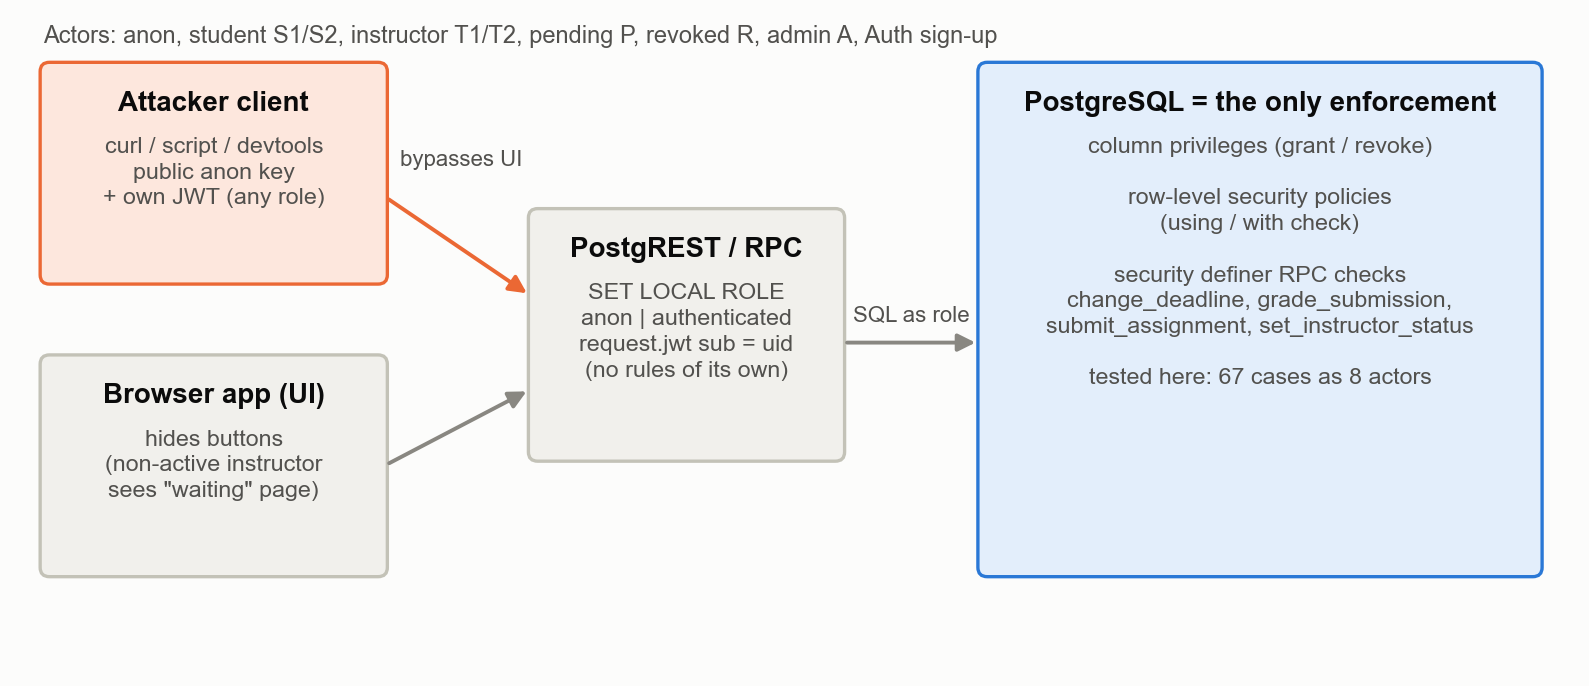

fig3-counterexample-flow.png


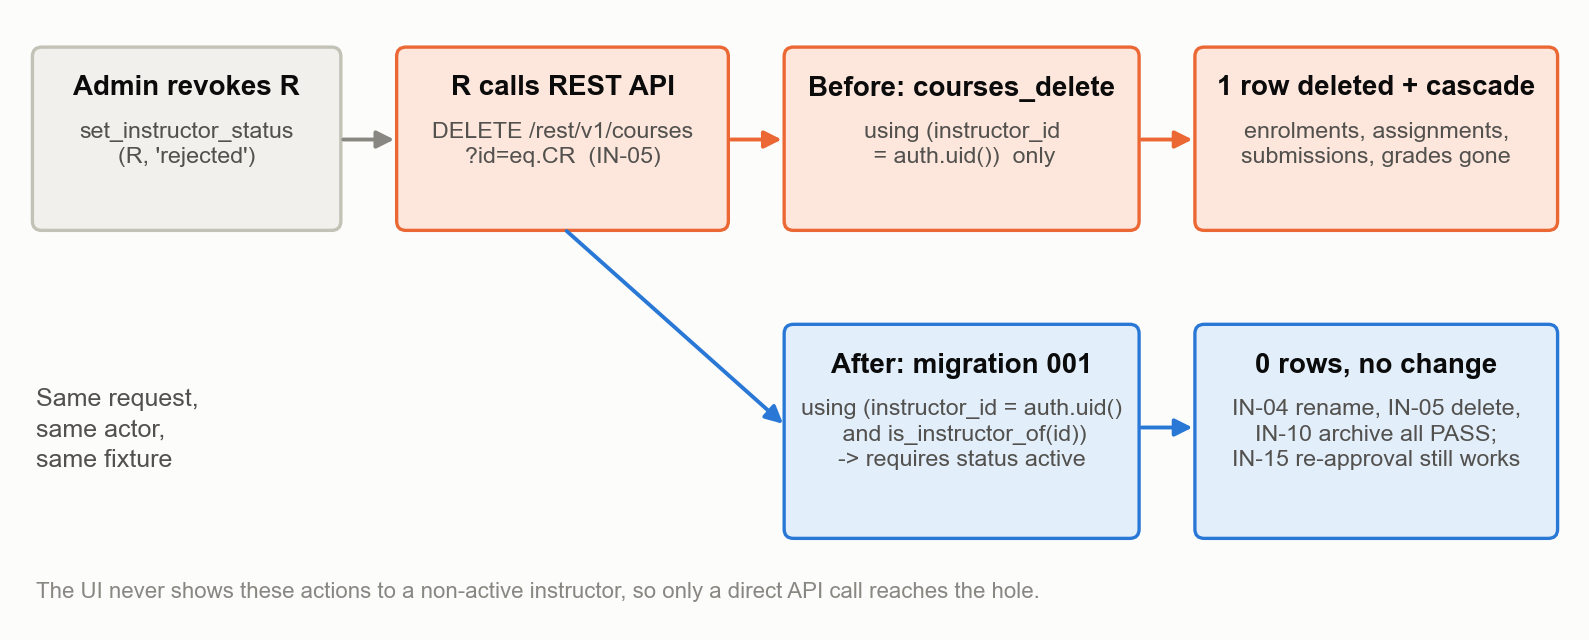

fig4-results.png


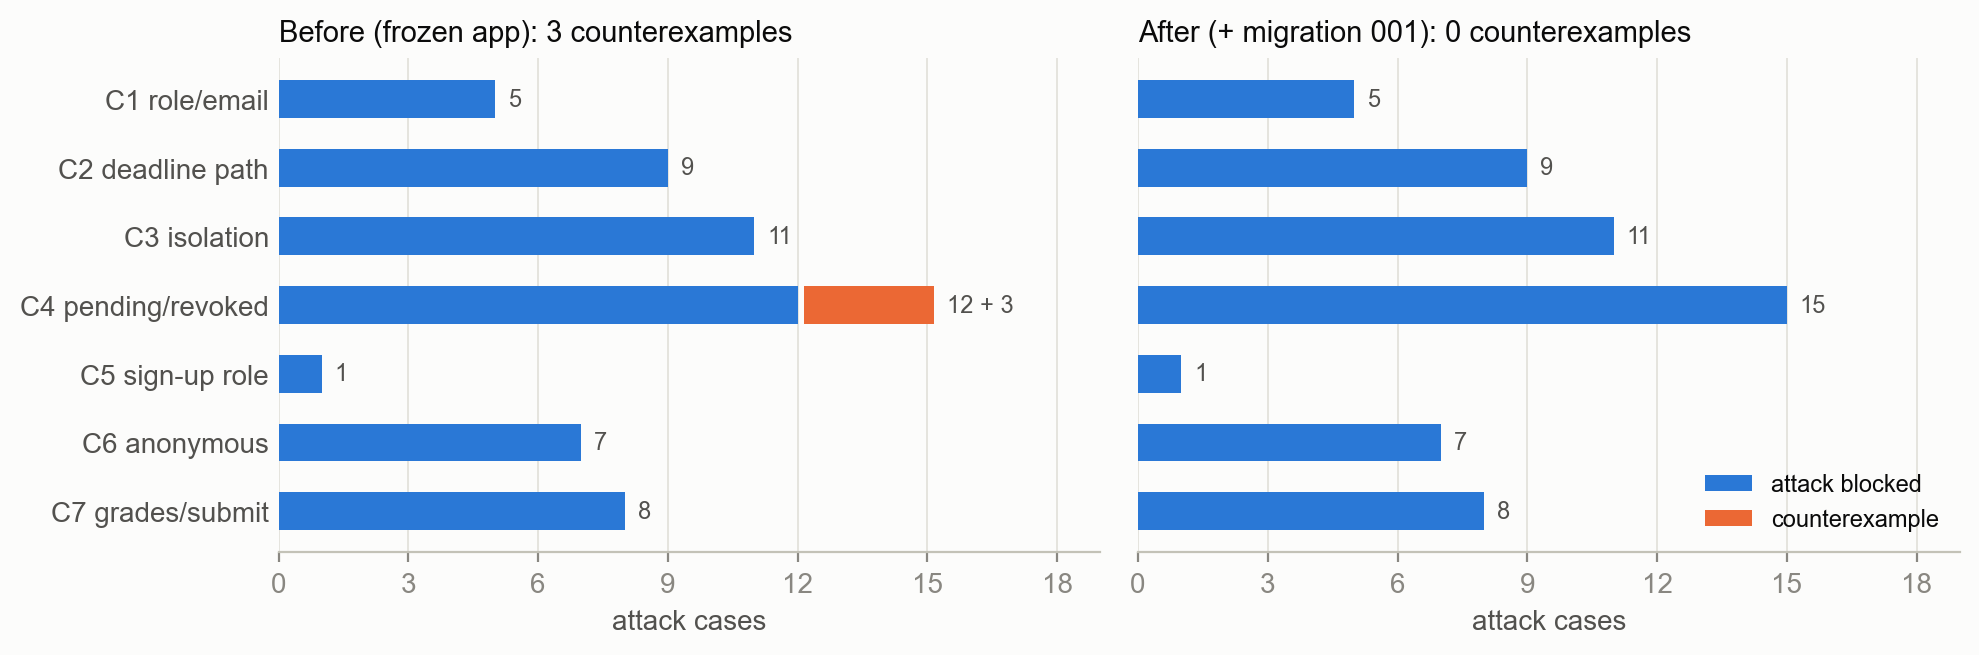

In [9]:
from IPython.display import Image, display
for f in sorted((ROOT / 'report' / 'figures').glob('*.png')):
    print(f.name); display(Image(filename=str(f), width=820))

## 8. Conclusion

- Sub-claim **C4** ("a pending or rejected instructor can manage nothing") is **falsified** on the frozen app:
  IN-04 rename, IN-05 delete (with cascade), IN-10 archive.
- One migration (two policies) removes all three. All 11 controls still pass, and no new counterexample appears.
- The other six sub-claims were **not falsified** by their 41 attack cases (the other 12 C4 attacks also held). The mutation score is 0.80, exactly at the
  threshold, and two survivors are explained in RESIDUAL-RISK.md. Not falsified does not mean proven.